# Preprocess a ramp

Before fitting, a raw ramp needs a set of corrections, all available on
`~mercupix.ramp.RawRamp` and chained by
`~mercupix.ramp.RawRamp.preprocess_ramp`:

1. reference pixel correction,
2. offset (bias) subtraction,
3. classical non-linearity correction,
4. inter-pixel capacitance (IPC) deconvolution,
5. dark subtraction,
6. data quality masking and cosmic ray correction.

This guide covers the reference pixels, the mask and the cosmic rays.

We use a small simulated ramp so that this page runs anywhere. The
`make_toy_ramp` helper is described in {doc}`howto_load_ramp`; with real data,
skip this cell and load your own file.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

import numpy as np
from astropy.io import fits

def make_toy_ramp(filename, ngroups=30, dt=2.8, size=128, nrefpixels=4, nchannels=4,
                  readnoise=10., bias=10_000., n_cosmics=30, seed=0):
    """Simulate a raw HxRG ramp in pyxim format and return the truth.

    The active area sees a flat background, a few stars (one of them
    saturating) and cosmic rays. All pixels, reference pixels included,
    share a per-channel and per-row offset that drifts from group to group.
    """
    rng = np.random.default_rng(seed)
    n = size + 2 * nrefpixels
    act = slice(nrefpixels, -nrefpixels)
    times = np.arange(1, ngroups + 1, dtype="float32") * dt

    # True flux [ADU/s] on the active area: background + stars.
    yy, xx = np.mgrid[:size, :size]
    flux = np.full((size, size), 5.)
    for y0, x0, amp in [(40, 40, 300.), (90, 30, 80.), (64, 100, 3_000.), (100, 90, 20.)]:
        flux += amp * np.exp(-((yy - y0)**2 + (xx - x0)**2) / (2 * 2.**2))

    # Accumulated photo-electrons (gain = 1) with Poisson noise.
    signal = np.zeros((ngroups, n, n))
    signal[:, act, act] = np.cumsum(rng.poisson(flux[None] * dt, (ngroups, size, size)), axis=0)

    # Cosmic rays: a jump that stays in the ramp from a random group onwards.
    cosmics = []
    for _ in range(n_cosmics):
        y, x, g = rng.integers(0, size), rng.integers(0, size), rng.integers(1, ngroups)
        amp = rng.uniform(300, 3_000)
        signal[g:, y + nrefpixels, x + nrefpixels] += amp
        cosmics.append((y, x, g, amp))

    # Correlated read noise seen by the reference pixels too.
    npix_channel = n // nchannels
    channel_offset = np.repeat(rng.normal(0, 30, (ngroups, nchannels)), npix_channel, axis=1)
    row_offset = rng.normal(0, 5, (ngroups, n))
    raw = (bias + signal + channel_offset[:, None, :] + row_offset[:, :, None]
           + rng.normal(0, readnoise, signal.shape))
    raw = np.clip(raw, 0, 65_535).astype("uint16")

    primary = fits.PrimaryHDU(raw)
    primary.header["NCHAN"] = nchannels
    table = fits.BinTableHDU.from_columns([fits.Column("readout_times", "E", array=times)])
    fits.HDUList([primary, table]).writeto(filename, overwrite=True)
    return dict(flux=flux, cosmics=cosmics, times=times, readnoise=readnoise)

truth = make_toy_ramp("toy_ramp.fits")

In [2]:
from mercupix.ramp import RawRamp

ramp = RawRamp.from_filename("toy_ramp.fits", datatype="pyxim")

## Reference pixel correction

`~mercupix.ramp.RawRamp.correct_refpix` estimates the correlated offsets from
the reference pixels and subtracts them:

- the **up-down** part is the mean of the top and bottom reference rows in
  each readout channel,
- the **left-right** part is the mean of the left and right reference columns
  in each row, smoothed along the rows.

The output is cropped to the active area.

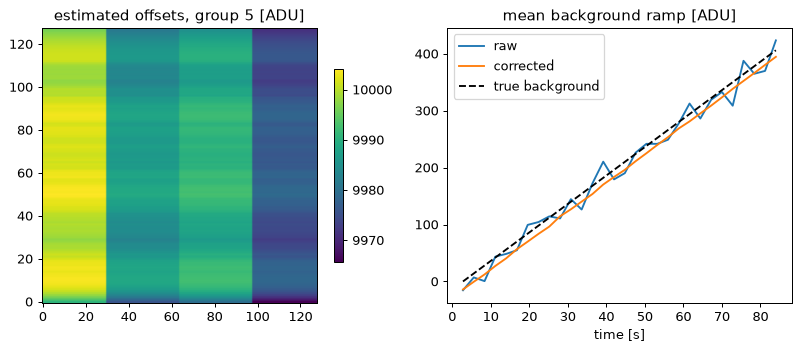

In [3]:
refmap = ramp.get_refpix_map()      # (ngroups, ny_act, nx_act)
corrected = ramp.correct_refpix()   # (ngroups, ny_act, nx_act)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
im = axes[0].imshow(refmap[5], origin="lower")
fig.colorbar(im, ax=axes[0], shrink=0.7)
axes[0].set_title("estimated offsets, group 5 [ADU]")

act = ramp.actslice
raw = ramp.data[:, act, act].astype("float32")
background = (slice(0, 20), slice(0, 128))      # star-free region
axes[1].plot(ramp.times, raw[:, background[0], background[1]].mean(axis=(1, 2)) - raw[0].mean(), label="raw")
axes[1].plot(ramp.times, corrected[:, background[0], background[1]].mean(axis=(1, 2)) - corrected[0].mean(), label="corrected")
axes[1].plot(ramp.times, 5 * (ramp.times - ramp.times[0]), "k--", label="true background")
axes[1].set_xlabel("time [s]")
axes[1].set_title("mean background ramp [ADU]")
axes[1].legend()
fig.tight_layout()
plt.show()

## Data quality mask

`~mercupix.ramp.RawRamp.get_mask` builds a bitmask. Each problem sets one bit,
as listed in {doc}`../concepts`. Here we flag saturated groups and cosmic rays;
disconnected and hot pixels need calibration files, so we turn them off.

In [4]:
data, var, mask = ramp.preprocess_ramp(
    corr_refpix=True,
    mask=True,
    mask_kwargs=dict(disconnected=False, saturated=True, cosmics=True),
)
print(data.shape, mask.shape, mask.dtype)

(30, 128, 128) (30, 128, 128) uint32


`~mercupix.mask.get_boolmask` turns the bitmask into a boolean mask. Use
`ignore_flags="~FLAG"` to keep a single flag.

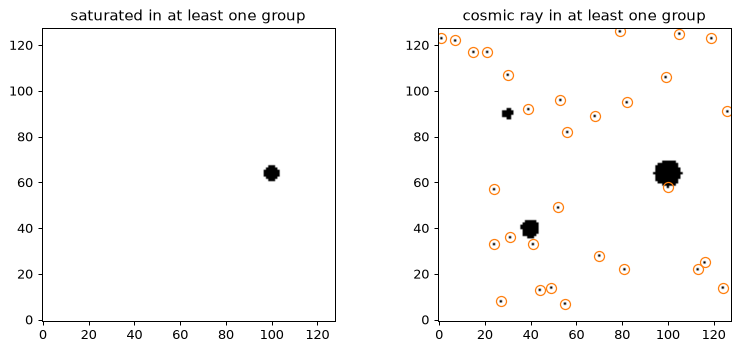

In [5]:
from mercupix.mask import get_boolmask

saturated = get_boolmask(mask, ignore_flags="~SATURATED")
cosmic = get_boolmask(mask, ignore_flags="~CR")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(saturated.any(axis=0), origin="lower", cmap="Greys")
axes[0].set_title("saturated in at least one group")
axes[1].imshow(cosmic.any(axis=0), origin="lower", cmap="Greys")
axes[1].set_title("cosmic ray in at least one group")
for y, x, g, amp in truth["cosmics"]:
    axes[1].plot(x, y, "o", mfc="none", mec="C1", ms=8)
fig.tight_layout()
plt.show()

The orange circles mark the simulated cosmic rays. The jump detection looks for
outliers in the group differences, relative to a moving median. The first
group has no difference: it is flagged by sigma clipping across the frame,
which also catches the bright stars. Use `cosmic[1:]` to look at the jumps
only.

## Correct the cosmic rays

With `corr_cosmics=True`, the flagged group differences are replaced by the
moving median and the ramp is rebuilt (*inpainting*). The ramp can then be
fitted as if it had not been hit.

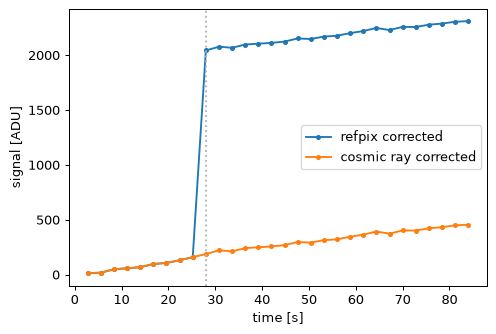

In [6]:
inpainted, _, _ = ramp.preprocess_ramp(
    corr_refpix=True, corr_cosmics=True,
    mask=True, mask_kwargs=dict(disconnected=False, cosmics=True),
)

y, x, g, amp = next(c for c in truth["cosmics"] if 8 <= c[2] <= 20)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ramp.times, data[:, y, x], ".-", label="refpix corrected")
ax.plot(ramp.times, inpainted[:, y, x], ".-", label="cosmic ray corrected")
ax.axvline(ramp.times[g], color="0.7", ls=":")
ax.set_xlabel("time [s]")
ax.set_ylabel("signal [ADU]")
ax.legend()
plt.show()

:::{tip}
Correcting the cosmic rays before the fit is one of two strategies. The
`~mercupix.fitter.Brandt2024` fitter can instead detect and drop jumps during
the fit. See {doc}`../methods/jumps` for a comparison.
:::

## Other corrections

The other steps use calibration data. Pass them directly, or give paths to the
calibration files through `metadata`:

```python
data, var, mask = ramp.preprocess_ramp(
    corr_offset=True, offset=superbias,             # 2D or 3D bias
    corr_nl=True, nl_coefficients=nl_coefs,         # increasing order
    corr_ipc=True, ipckernel=kernel,                # (1, k, k) kernel
    corr_dark=True, darkdata=dark_rate,             # 2D rate or 3D cube
)
```

Next: {doc}`howto_fit_ramp`.